In [78]:
X_config = ["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
     "dir_viento_carrasco_prom","int_viento_carrasco_prom",
     "int_racha_viento_carrasco_prom","dir_viento_salto_prom","int_viento_salto_prom",
     "int_racha_viento_salto_prom","vis_carrasco_prom","vis_salto_prom","fen_carrasco_17", "fase_lunar"]


y_config = ["dia_lluvioso"]

In [ ]:
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Carga dataset
S = t.cargarDataset("data_dia1")

# Configuración atributos y objetivo válidos
X = S[X_config]

y = S[y_config].squeeze() #pasa de df a serie

# #configuración de hiperparámetros a evaluar
criterios = ["gain", "gini", "gain_ratio"]
min_info_gains = [0.003, 0.004, 0.006, 0.008]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_id3, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, criterios=criterios, hiperparams=min_info_gains)

print("\n Resultados CV")
print(df_validacion_id3.round(4).to_string(index=False))
#tiempo est: 28min

#Se puede reducir criterios y min_info_gain para hacerlo más veloz, configuracion hallada:
# Resultados CV
#   criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
#       gain          0.003         0.6988        0.0059   0.2806  0.0120       0.2652      0.0135          0.2981         0.0120
#       gain          0.004         0.6990        0.0059   0.2802  0.0128       0.2646      0.0150          0.2981         0.0120
#       gain          0.006         0.7022        0.0050   0.2708  0.0140       0.2499      0.0176          0.2960         0.0104
#       gain          0.008         0.7045        0.0072   0.2689  0.0128       0.2454      0.0154          0.2978         0.0130
#       gini          0.003         0.7031        0.0053   0.2801  0.0141       0.2610      0.0178          0.3027         0.0107
#       gini          0.004         0.7135        0.0061   0.2746  0.0097       0.2449      0.0118          0.3130         0.0109
#       gini          0.006         0.7305        0.0097   0.2456  0.0171       0.1987      0.0222          0.3247         0.0147
#       gini          0.008         0.7530        0.0032   0.2105  0.0247       0.1495      0.0232          0.3603         0.0103
# gain_ratio          0.003         0.6982        0.0080   0.2829  0.0139       0.2688      0.0148          0.2989         0.0156
# gain_ratio          0.004         0.6991        0.0078   0.2813  0.0162       0.2660      0.0188          0.2989         0.0159
# gain_ratio          0.006         0.7066        0.0100   0.2688  0.0101       0.2435      0.0136          0.3008         0.0149
# gain_ratio          0.008         0.7232        0.0097   0.2463  0.0175       0.2043      0.0167          0.3111         0.0237 


 Resultados CV
  criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
      gain          0.003         0.6988        0.0059   0.2806  0.0120       0.2652      0.0135          0.2981         0.0120
      gain          0.004         0.6990        0.0059   0.2802  0.0128       0.2646      0.0150          0.2981         0.0120
      gain          0.006         0.7022        0.0050   0.2708  0.0140       0.2499      0.0176          0.2960         0.0104
      gain          0.008         0.7045        0.0072   0.2689  0.0128       0.2454      0.0154          0.2978         0.0130
      gini          0.003         0.7031        0.0053   0.2801  0.0141       0.2610      0.0178          0.3027         0.0107
      gini          0.004         0.7135        0.0061   0.2746  0.0097       0.2449      0.0118          0.3130         0.0109
      gini          0.006         0.7305        0.0097   0.2456  0.0171       0.1987    

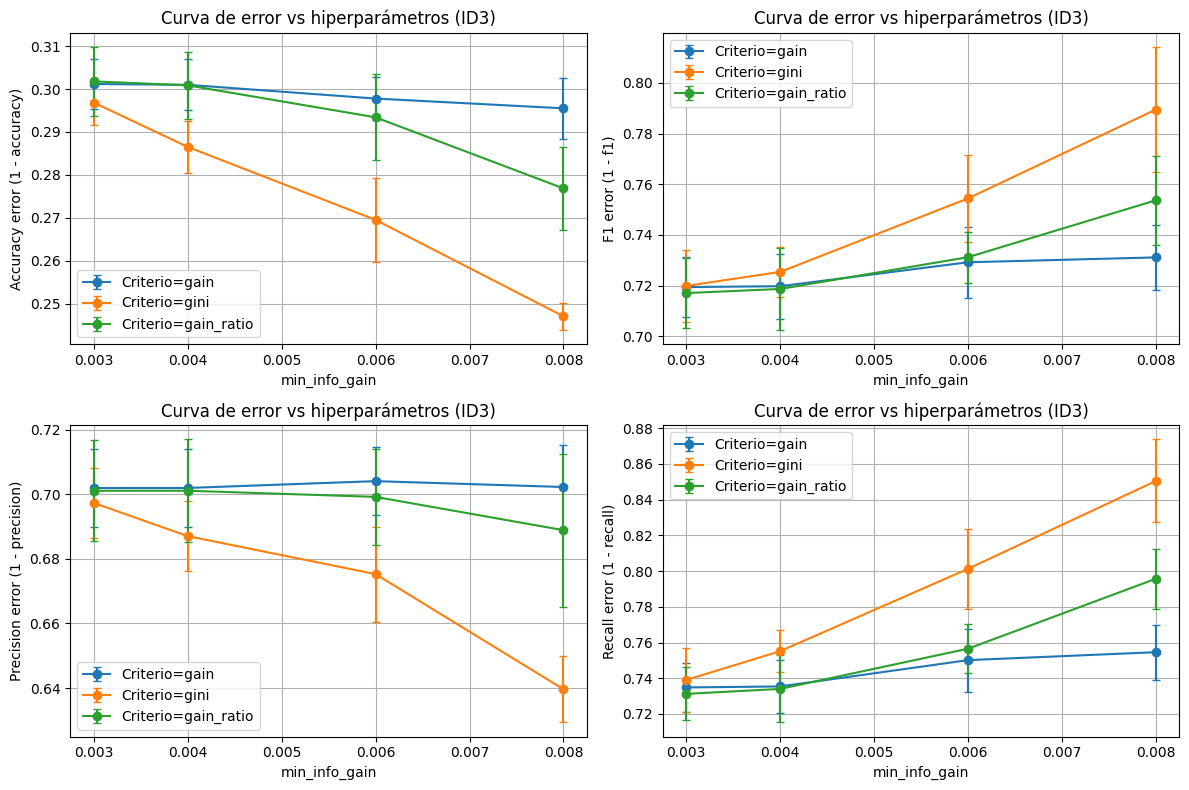

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_id3, metric="accuracy", modelo="ID3", ax=axs[0,0])
t.funcGraficaError(df_validacion_id3, metric="f1", modelo="ID3", ax=axs[0,1])
t.funcGraficaError(df_validacion_id3, metric="precision", modelo="ID3", ax=axs[1,0])
t.funcGraficaError(df_validacion_id3, metric="recall", modelo="ID3", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain_ratio mejor min_info_gain:  0.003
Accuracy : 0.7056650246305419
F1       : 0.29080118694362017
Recall   : 0.2722222222222222
Precision: 0.31210191082802546

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gini mejor min_info_gain:  0.008
Accuracy : 0.746551724137931
F1       : 0.1774580335731415
Recall   : 0.12333333333333334
Precision: 0.3162393162393162

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


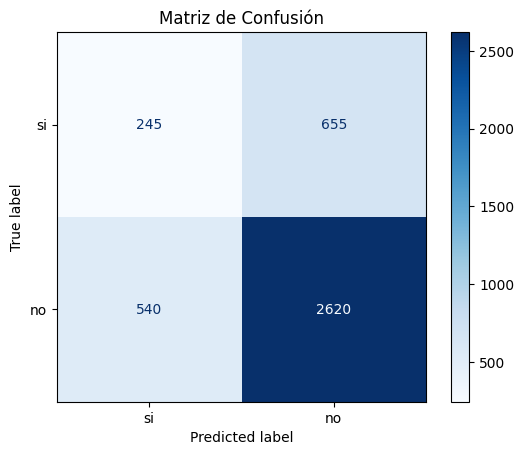


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


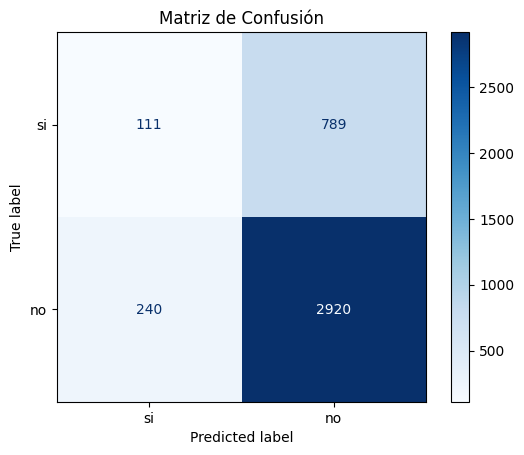

In [81]:
# Evaluación final en test según mejores configuraciones ID3 modificado
y_pred_f = t.testearModelo("ID3", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("ID3", best_cfg_F, y_test, y_pred_f)

y_pred_a = t.testearModelo("ID3", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("ID3", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
t.graficar_matriz_confusion(y_test, y_pred_f, labels=['si', 'no'])

print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
t.graficar_matriz_confusion(y_test, y_pred_a, labels=['si', 'no'])

#timepo est: 1min

In [82]:
#PRINT ARBOL ID3, descomentar si se prefiere, resulta un arbol muy amplio

# arbol = t.generacion_ID3(S, list(X.columns), "dia_lluvioso", best_cfg_F["min_info_gain"], best_cfg_F["criterio"])
# dot = t.graficar_arbol(arbol)
# dot.render("ARBOL mejor parametrización según f-score", format="png", view=True)

In [83]:
# -------------------------------------------- RANDOM FOREST -------------------------------------------------
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Cargar dataset
S2 = t.cargarDataset("data_dia_c")

# Definir los atributos y objetivo validos
# Configuración atributos y objetivo válidos
X_config.remove("fase_lunar") #eliminamos la fase lunar
X = S2[X_config]

y = S2[y_config].squeeze() #pasa de df a serie

#configuración de hiperparámetros a evaluar
n_estimators_values = [100, 200, 300, 500]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_rf, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, hiperparams=n_estimators_values)

print("\n Resultados CV")
print(df_validacion_rf.round(4).to_string(index=False))

#tiempo est: 2 min



 Resultados CV
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.7781        0.0047   0.1478  0.0223       0.0870      0.0141          0.4969         0.0576
          200         0.7788        0.0045   0.1439  0.0133       0.0839      0.0083          0.5104         0.0592
          300         0.7799        0.0037   0.1423  0.0128       0.0825      0.0087          0.5290         0.0567
          500         0.7797        0.0039   0.1395  0.0075       0.0806      0.0050          0.5259         0.0608


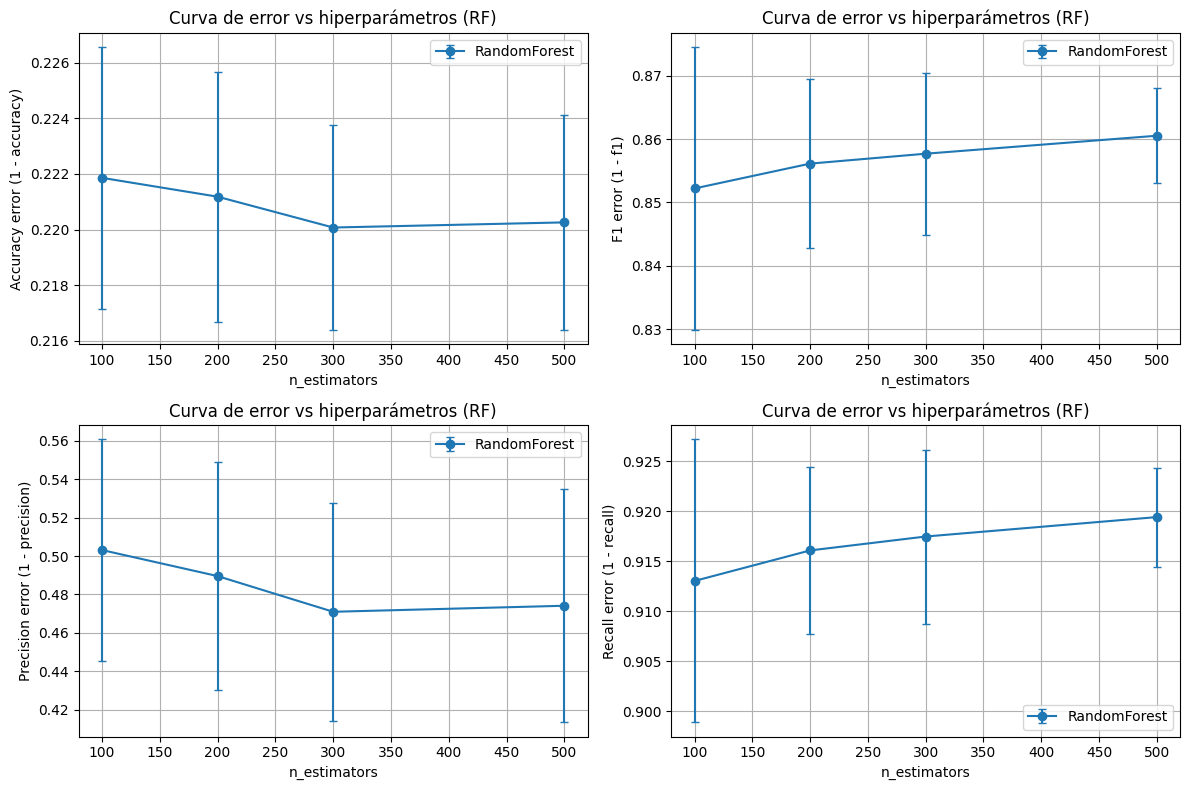

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_rf, metric="accuracy", modelo="RF", ax=axs[0,0])
t.funcGraficaError(df_validacion_rf, metric="f1", modelo="RF", ax=axs[0,1])
t.funcGraficaError(df_validacion_rf, metric="precision", modelo="RF", ax=axs[1,0])
t.funcGraficaError(df_validacion_rf, metric="recall", modelo="RF", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  100
Accuracy : 0.7738916256157635
F1       : 0.16998191681735986
Recall   : 0.4563106796116505
Precision: 0.10444444444444445

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  300
Accuracy : 0.7729064039408867
F1       : 0.15722120658135283
Recall   : 0.09555555555555556
Precision: 0.44329896907216493

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


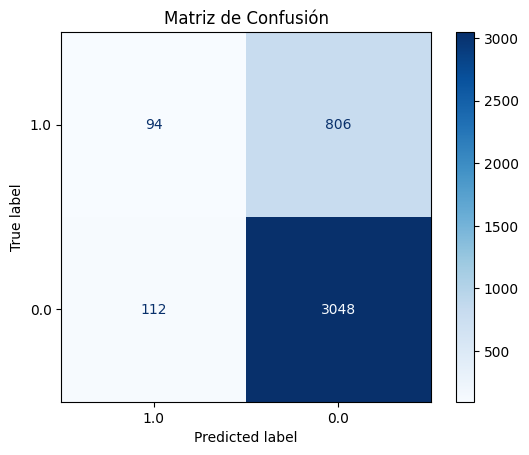


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


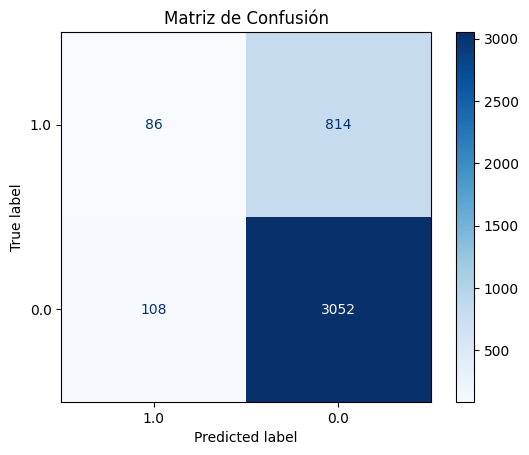

In [ ]:
# Evaluación final en test según mejores configuraciones RANDOM FOREST sickit learn
y_pred_f = t.testearModelo("RF", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("RF", best_cfg_F, y_pred_f, y_test)

y_pred_a = t.testearModelo("RF", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("RF", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
t.graficar_matriz_confusion(y_test, y_pred_f, labels=[1.0, 0.0])

print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
t.graficar_matriz_confusion(y_test, y_pred_a, labels=[1.0, 0.0])

#tiempo est: 10seg